##### KAYENY MIRIAM MELODY YUNG S26M19/049
## Fetching and Displaying a Weather Forecast with Python Web APIs
The Weather Forecast Application is a Python program that retrieves weather information for a location specified by the user. It uses the Open-Meteo Geocoding API to convert a place name into geographical coordinates, the Open-Meteo Forecast API to obtain weather predictions, and the MET Norway Locationforecast API as a secondary source. An Artificial intelligence tool(CODEX)was used to edit the code.

In [2]:
LOCATION = "Mpererwe"
CONTACT_EMAIL = "b40823@students.ucu.ac.ug"
FORECAST_DAYS = 7

In [3]:
import json
import time
import urllib.parse
import urllib.request
from datetime import datetime

import requests
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
#using urllib
url = "https://geocoding-api.open-meteo.com/v1/search"
params = {"name": "Dresden","count": 5,"language": "en","format": "json"}
query_string = urllib.parse.urlencode(params)
full_url = url + "?" + query_string
request = urllib.request.Request(full_url,headers={"Accept": "application/json"})
start = time.perf_counter()
with urllib.request.urlopen(request, timeout=10) as response:
    body = response.read().decode("utf-8")
    data = json.loads(body)

    print("Status:", response.status)
    print("Content-Type:", response.headers.get("Content-Type"))
    print("Response time:", round(time.perf_counter() - start, 3), "seconds")

print(json.dumps(data, indent=2))

Status: 200
Content-Type: application/json; charset=utf-8
Response time: 1.339 seconds
{
  "results": [
    {
      "id": 2935022,
      "name": "Dresden",
      "latitude": 51.05089,
      "longitude": 13.73832,
      "elevation": 116.0,
      "feature_code": "PPLA",
      "country_code": "DE",
      "admin1_id": 2842566,
      "admin3_id": 2935020,
      "admin4_id": 6551127,
      "timezone": "Europe/Berlin",
      "population": 556227,
      "country_id": 2921044,
      "country": "Germany",
      "admin1": "Saxony",
      "admin3": "Kreisfreie Stadt Dresden",
      "admin4": "Dresden"
    },
    {
      "id": 4619013,
      "name": "Dresden",
      "latitude": 36.29145,
      "longitude": -88.70811,
      "elevation": 130.0,
      "feature_code": "PPLA2",
      "country_code": "US",
      "admin1_id": 4662168,
      "admin2_id": 4666265,
      "timezone": "America/Chicago",
      "population": 2898,
      "postcodes": [
        "38225"
      ],
      "country_id": 6252001,
      "

In [5]:
#using requests
response = requests.get(url,params=params,timeout=10)
print("Status:", response.status_code)
print("Content-Type:", response.headers.get("Content-Type"))
print("Response time:", round(response.elapsed.total_seconds(), 3), "seconds")

response.raise_for_status()
data_requests = response.json()

print(json.dumps(data_requests, indent=2))

Status: 200
Content-Type: application/json; charset=utf-8
Response time: 0.842 seconds
{
  "results": [
    {
      "id": 2935022,
      "name": "Dresden",
      "latitude": 51.05089,
      "longitude": 13.73832,
      "elevation": 116.0,
      "feature_code": "PPLA",
      "country_code": "DE",
      "admin1_id": 2842566,
      "admin3_id": 2935020,
      "admin4_id": 6551127,
      "timezone": "Europe/Berlin",
      "population": 556227,
      "country_id": 2921044,
      "country": "Germany",
      "admin1": "Saxony",
      "admin3": "Kreisfreie Stadt Dresden",
      "admin4": "Dresden"
    },
    {
      "id": 4619013,
      "name": "Dresden",
      "latitude": 36.29145,
      "longitude": -88.70811,
      "elevation": 130.0,
      "feature_code": "PPLA2",
      "country_code": "US",
      "admin1_id": 4662168,
      "admin2_id": 4666265,
      "timezone": "America/Chicago",
      "population": 2898,
      "postcodes": [
        "38225"
      ],
      "country_id": 6252001,
      "

In [6]:
#custom exception and http function
class APIRequestError(Exception):
    """API request has failed after all retries."""
def request_json(url: str,params: dict | None = None,headers: dict | None = None,timeout: float = 10,retries: int = 3) -> dict:
    """Request JSON from an API, retrying temporary failures."""
    for attempt in range(retries):
        try:
            response = requests.get(url,params=params,headers=headers,timeout=timeout)
            if 500 <= response.status_code < 600:
                response.raise_for_status()
            response.raise_for_status()
            return response.json()

        except (requests.ConnectionError,requests.Timeout,requests.HTTPError,requests.JSONDecodeError) as error:

            retryable = (isinstance(error, (requests.ConnectionError,requests.Timeout,requests.JSONDecodeError))
                or (isinstance(error, requests.HTTPError)
                    and error.response is not None
                    and error.response.status_code >= 500))

            if not retryable:
                raise APIRequestError(f"Request failed: {error}") from error

            if attempt == retries - 1:
                raise APIRequestError(f"Request failed after {retries} attempts: {error}") from error

            time.sleep(2 ** attempt)

    raise APIRequestError("Request failed unexpectedly.")

In [7]:
#location
def geocode(name: str) -> list[dict]:
    """Return locations for a place name."""
    data = request_json("https://geocoding-api.open-meteo.com/v1/search",
        params={"name": name,"count": 10,"language": "en","format": "json"})

    return data.get("results", [])

In [8]:
candidates = geocode(LOCATION)
if not candidates:
    raise ValueError(f"No locations found for {LOCATION!r}. ""Check the spelling or try another name." )
for i, place in enumerate(candidates):
    print(i,place["name"],place.get("admin1", ""),place.get("country", ""),place["latitude"],place["longitude"])
if len(candidates) == 1:
    selected = candidates[0]
else:
    selected = candidates[0]
    print("Multiple candidates found.")
    print("The first candidate is selected automatically.")
    print("Change the configuration cell to refine the location.")

latitude = selected["latitude"]
longitude = selected["longitude"]
place_name = selected["name"]
timezone_name = selected.get("timezone", "auto")

print("Selected:", place_name)
print("Coordinates:", latitude, longitude)

0 Mpererwe Central Region Uganda 0.4 32.57
Selected: Mpererwe
Coordinates: 0.4 32.57


In [9]:
#daily forecast
def get_forecast(lat: float,lon: float,days: int = 7) -> dict:
    """Retrieve daily weather forecasts from Open-Meteo."""
    if not -90 <= lat <= 90:
        raise ValueError("Latitude must be between -90 and 90.")

    if not -180 <= lon <= 180:
        raise ValueError("Longitude must be between -180 and 180.")

    if not 1 <= days <= 16:
        raise ValueError("Days must be between 1 and 16.")

    return request_json(
        "https://api.open-meteo.com/v1/forecast",
        params={"latitude": round(lat, 4),"longitude": round(lon, 4),
            "daily": ["temperature_2m_max","temperature_2m_min","precipitation_sum","wind_speed_10m_max","weather_code"],
            "forecast_days": days,"timezone": timezone_name},timeout=10)

In [10]:
#open meteo weather codes
WEATHER_CODES = {
    0: "Clear sky",
    1: "Mainly clear",
    2: "Partly cloudy",
    3: "Overcast",
    45: "Fog",
    48: "Depositing rime fog",
    51: "Light drizzle",
    53: "Moderate drizzle",
    55: "Dense drizzle",
    56: "Light freezing drizzle",
    57: "Dense freezing drizzle",
    61: "Slight rain",
    63: "Moderate rain",
    65: "Heavy rain",
    66: "Light freezing rain",
    67: "Heavy freezing rain",
    71: "Slight snow",
    73: "Moderate snow",
    75: "Heavy snow",
    77: "Snow grains",
    80: "Slight rain showers",
    81: "Moderate rain showers",
    82: "Violent rain showers",
    85: "Slight snow showers",
    86: "Heavy snow showers",
    95: "Thunderstorm",
    96: "Thunderstorm with slight hail",
    99: "Thunderstorm with heavy hail"
}


def weather_description(code: int) -> str:
    """Convert a WMO weather code into readable text."""
    return WEATHER_CODES.get(code, "Unknown weather condition")

In [11]:
def parse_forecast(data: dict) -> pd.DataFrame:
    """Convert daily forecast JSON to a labelled DataFrame."""
    daily = data["daily"]

    return pd.DataFrame({"Date": daily["time"],"Minimum temperature (°C)": daily["temperature_2m_min"],
        "Maximum temperature (°C)": daily["temperature_2m_max"],"Precipitation (mm)": daily["precipitation_sum"],
        "Maximum wind speed (km/h)": daily["wind_speed_10m_max"],"Weather": [weather_description(code)for code in daily["weather_code"]]})

In [12]:
forecast_data = get_forecast(latitude,longitude,FORECAST_DAYS)
forecast_df = parse_forecast(forecast_data)

print(f"Weather forecast for {place_name}")
print(forecast_df.to_string(index=False))

average_max = forecast_df["Maximum temperature (°C)"].mean()
average_min = forecast_df["Minimum temperature (°C)"].mean()
total_rain = forecast_df["Precipitation (mm)"].sum()

print(f"\nForecast summary for {place_name}")
print(f"Average daily maximum: {average_max:.1f} °C")
print(f"Average daily minimum: {average_min:.1f} °C")
print(f"Total forecast precipitation: {total_rain:.1f} mm")
print("Warmest forecast day:",forecast_df.loc[forecast_df["Maximum temperature (°C)"].idxmax(), "Date"])
print("Source: Open-Meteo Forecast API (open-meteo.com)")

Weather forecast for Mpererwe
      Date  Minimum temperature (°C)  Maximum temperature (°C)  Precipitation (mm)  Maximum wind speed (km/h)               Weather
2026-10-11                      18.7                      25.6                21.9                       13.3          Thunderstorm
2026-10-12                      18.5                      25.8                 5.7                       11.9 Moderate rain showers
2026-10-13                      19.6                      25.9                 1.7                       11.5      Moderate drizzle
2026-10-14                      18.1                      27.4                 4.1                       13.3 Moderate rain showers
2026-10-15                      18.8                      26.6                 4.2                        9.3      Moderate drizzle
2026-10-16                      18.7                      24.6                15.9                        9.9   Slight rain showers
2026-10-17                      18.4          

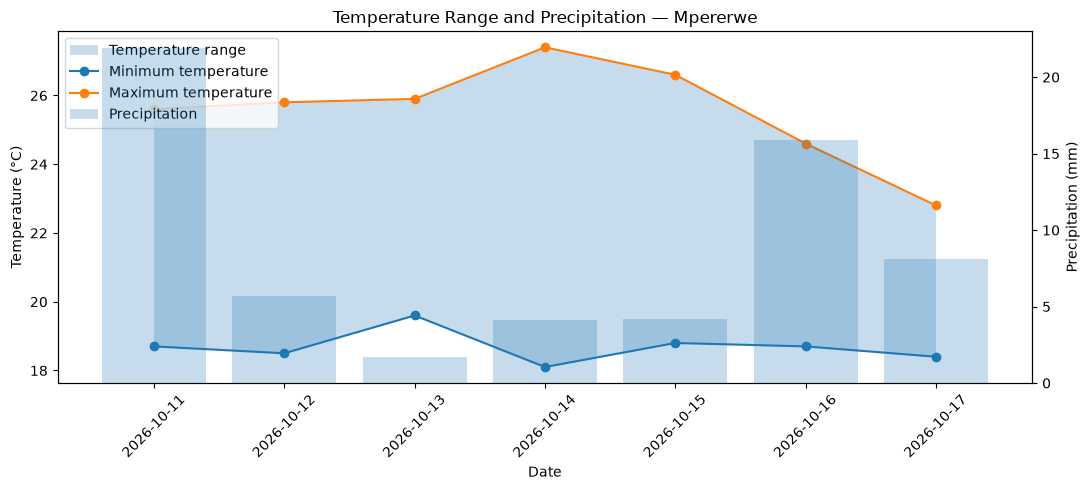

In [13]:
#visuals
fig, ax1 = plt.subplots(figsize=(11, 5))
dates = forecast_df["Date"]
minimum = forecast_df["Minimum temperature (°C)"]
maximum = forecast_df["Maximum temperature (°C)"]

ax1.fill_between(dates, minimum, maximum, alpha=0.25,label="Temperature range")
ax1.plot(dates, minimum, marker="o", label="Minimum temperature")
ax1.plot(dates, maximum, marker="o", label="Maximum temperature")
ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.bar(dates, forecast_df["Precipitation (mm)"],alpha=0.25,label="Precipitation")
ax2.set_ylabel("Precipitation (mm)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title(f"Temperature Range and Precipitation — {place_name}")
fig.tight_layout()
plt.show()

In [14]:
#MET norway
def get_met_forecast(lat: float, lon: float) -> dict:
    """Retrieve a forecast from MET Norway."""
    if not -90 <= lat <= 90:
        raise ValueError("Latitude must be between -90 and 90.")

    if not -180 <= lon <= 180:
        raise ValueError("Longitude must be between -180 and 180.")

    if not CONTACT_EMAIL or CONTACT_EMAIL == "YOUR_REAL_UNIVERSITY_EMAIL":
        raise ValueError("Enter your real contact email in Cell 2.")

    headers = {"User-Agent": f"StudentWeatherForecast/1.0 ({CONTACT_EMAIL})","Accept": "application/json"}

    return request_json("https://api.met.no/weatherapi/locationforecast/2.0/compact",
        params={"lat": round(lat, 4),"lon": round(lon, 4)},headers=headers,timeout=10)

In [15]:
def parse_met_forecast(data: dict) -> pd.DataFrame:
    """Extract daily representative values from MET time series."""
    records = {}

    for item in data["properties"]["timeseries"]:
        timestamp = item["time"]
        date = timestamp[:10]

        instant = item["data"]["instant"]["details"]
        next_data = item["data"].get("next_1_hours", {})
        next_details = next_data.get("details", {})

        if date not in records:
            records[date] = {"Date": date,"Temperature (°C)": instant.get("air_temperature"),"Wind speed (m/s)": instant.get("wind_speed"),
                "Precipitation (mm)": next_details.get("precipitation_amount")}

    return pd.DataFrame(list(records.values()))

In [16]:
try:
    met_data = get_met_forecast(latitude, longitude)
    met_df = parse_met_forecast(met_data)

    print("MET Norway forecast")
    print(met_df.head(FORECAST_DAYS).to_string(index=False))
    print("\nSource: MET Norway Locationforecast 2.0 ""(api.met.no)")

except (APIRequestError, ValueError, KeyError) as error:
    print("MET Norway forecast unavailable:", error)

MET Norway forecast
      Date  Temperature (°C)  Wind speed (m/s)  Precipitation (mm)
2026-10-11              23.8               2.2                 0.0
2026-10-12              19.3               3.5                 0.0
2026-10-13              19.8               3.7                 0.0
2026-10-14              19.0               2.4                 0.0
2026-10-15              19.3               2.6                 NaN
2026-10-16              18.9               3.2                 NaN
2026-10-17              18.3               1.2                 NaN

Source: MET Norway Locationforecast 2.0 (api.met.no)


In [17]:
#offline test
SAMPLE_JSON = {"daily": {"time": ["2026-10-11", "2026-10-12"],"temperature_2m_max": [28.0, 27.0],"temperature_2m_min": [19.0, 18.0],
        "precipitation_sum": [2.5, 0.0],"wind_speed_10m_max": [12.0, 15.0],"weather_code": [1, 61]}}

In [18]:
sample_df = parse_forecast(SAMPLE_JSON)

# Test 1: Two days should be parsed.
assert len(sample_df) == 2

# Test 2: Maximum temperature should be correct.
assert sample_df.loc[0, "Maximum temperature (°C)"] == 28.0

# Test 3: Minimum temperature should be correct.
assert sample_df.loc[1, "Minimum temperature (°C)"] == 18.0

# Test 4: Precipitation should be preserved.
assert sample_df.loc[0, "Precipitation (mm)"] == 2.5

# Test 5: Weather codes should become descriptions.
assert sample_df.loc[0, "Weather"] == "Mainly clear"

# Additional test 6: Unknown codes should not crash parsing.
assert weather_description(999) == "Unknown weather condition"

# Additional test 7: Invalid latitude should be rejected.
try:
    get_forecast(100, 32, 7)
    assert False, "Expected invalid latitude to raise ValueError"
except ValueError:
    pass

print("All offline tests passed.")

All offline tests passed.


In [19]:
#failure handling
try:
    results = geocode("zzzz_no_such_city_12345")

    if not results:
        print("Handled correctly: no matching location found.")

except APIRequestError as error:
    print("API request failed:", error)

Handled correctly: no matching location found.


In [20]:
try:
    get_forecast(999, 32, 7)
except ValueError as error:
    print("Handled correctly:", error)

Handled correctly: Latitude must be between -90 and 90.


In [21]:
original_get = requests.get

def simulated_network_failure(*args, **kwargs):
    raise requests.ConnectionError("Simulated network unavailable")
try:
    requests.get = simulated_network_failure

    try:
        request_json("https://example.invalid/weather",retries=2)
    except APIRequestError as error:
        print("Handled simulated network failure:", error)

finally:
    requests.get = original_get

Handled simulated network failure: Request failed after 2 attempts: Simulated network unavailable


In [22]:
try:
    request_json("https://api.open-meteo.com/v1/forecast",
        params={"latitude": 0,"longitude": 0,"daily": "temperature_2m_max"},timeout=0.000001,retries=2)

except APIRequestError as error:
    print("Tiny-timeout test ended with:", error)

Tiny-timeout test ended with: Request failed after 2 attempts: HTTPSConnectionPool(host='api.open-meteo.com', port=443): Max retries exceeded with url: /v1/forecast?latitude=0&longitude=0&daily=temperature_2m_max (Caused by ConnectTimeoutError(<HTTPSConnection(host='api.open-meteo.com', port=443) at 0x146a0eb6490>, 'Connection to api.open-meteo.com timed out. (connect timeout=1e-06)'))


### Data Flow
USER INPUT (LOCATION)----> Using urllib and requests to access the geocoding website so as to obtain the location's latitude and longitude----> Obtaining the latitude, longitude and timezone of the selected location----> Getting the daily forecast for the selceted location---> visulaisation of the temperature and precipitation of the selected location----> Secondary source retrieval from MET NORWAY

### The licensing and usage terms of each API
#### Open-Meteo Geocoding and Forecast APIs
- The Open-Meteo Geocoding API and Forecast API are used to retrieve weather predictions of locations.
- Open-Meteo makes its API data available under the Creative Commons Attribution 4.0 International licence (CC BY 4.0). This licence permits users to share, redistribute, and adapt the data, including for commercial purposes, provided that the licence conditions are followed. Appropriate credit must be given, a link to the licence must be provided, and changes to the data must be indicated where applicable. Attribution must not imply that Open-Meteo endorses the application.
- Open-Meteo's free API is restricted to non-commercial use, with stated limits of fewer than 10,000 API calls per day, 5,000 per hour, and 600 per minute. Educational projects and public research are among the examples of non-commercial use.
- Applications that display advertisements, charge subscriptions, or incorporate the service into commercial products may require a paid plan or separate commercial arrangement. These terms should be checked again before deployment because service conditions may change.
- Attribution should appear wherever weather information is presented.
- The API's source-code licence is separate from the licence governing its weather data. Open-Meteo's source code is distributed under the GNU Affero General Public License version 3 or later, while its API data use CC BY 4.0. A developer reusing the API data should distinguish these two licences rather than assuming that the source-code licence automatically governs the returned data.
#### MET Norway Locationforecast API
- MET Norway provides the Locationforecast API for retrieving forecasts for geographical coordinates.
- Its weather data are available under open-data licensing, including Creative Commons Attribution 4.0 International and the Norwegian Licence for Open Government Data, subject to the applicable product and service conditions. 
- The attribution requirement means that a product should clearly identify MET Norway as a source of the weather information. For example, it can state “Weather data from MET Norway” near the relevant forecast. If the data are transformed, the product should explain that the displayed values are processed or derived from the original data when appropriate.
- MET Norway also requires requests to identify the application through a meaningful User-Agent header containing application identification and contact information. Developers must avoid unnecessary traffic, respect service guidance, and use caching where appropriate. The service does not guarantee uninterrupted delivery or provide a general service-level agreement for the public API. Therefore, an application should not assume that every request will succeed.
- The MET Norway service is intended to make weather information openly accessible, including for commercial use, but open data licensing does not remove the technical and operational requirements governing access. A real product must comply with attribution, identification, traffic-management, and other applicable service conditions.




### Reliability issues and how they were handled
A weather application depends on external services and network communication. Consequently, it may encounter problems even when the Python code is correct. These problems include internet interruptions, slow responses, invalid inputs, ambiguous location names, unsuccessful HTTP responses, unexpected JSON structures, and differences between weather providers.
Some of these issues were handled below;
- The reusable request_json() fun() function specifies a timeout for each HTTP request. If the connection fails or the timeout is exceeded, the function catches the corresponding exception and attempts another request when appropriate. After the permitted attempts are exhausted, it raises an APIRequestError.
- Incase a user enters a location name that cannot be found the geocoding API may omit the results field entirely. Using data.get("results", []) safely handles a missing field by returning an empty list. The application can then explain that no matching location was found rather than raising an unexpected KeyError.
- Latitude must fall between -90 and 90 degrees, while longitude must fall between -180 and 180 degrees and these are checekd using the  get_forecast() function before sending the request. Invalid coordinates raise a ValueError, preventing unnecessary API calls.
- Assertion-based tests verify that the correct number of records is produced, temperature and precipitation values are preserved, weather codes are decoded, and invalid coordinates are rejected without internet connectivity.


### The privacy implications of sending location queries to third parties
- Sharing location queries to third parties poses privacy risks as personal information can be accessed by strangers and used for malicious activities like salking.
- Eventhough some sites state that they do not collect or share personal data through their service,it is no guarantee that no technical information can be processed anywhere in the network.
- Relying on third parties depends on their availability and privacy policies with some collecting more information than necessary.



In [1]:
#Json
import requests
import json

url = "https://geocoding-api.open-meteo.com/v1/search"
params = {"name": "Luweero","count": 10,"language": "en","format": "json"}
response = requests.get(url, params=params, timeout=10)
response.raise_for_status()
geocoding_data = response.json()
print(json.dumps(geocoding_data, indent=4))

{
    "results": [
        {
            "id": 8581570,
            "name": "Luweero",
            "latitude": 0.83339,
            "longitude": 32.4994,
            "elevation": 1118.0,
            "feature_code": "PPLS",
            "country_code": "UG",
            "admin1_id": 234594,
            "admin2_id": 443350,
            "admin3_id": 8644176,
            "admin4_id": 8657693,
            "timezone": "Africa/Kampala",
            "country_id": 226074,
            "country": "Uganda",
            "admin1": "Central Region",
            "admin2": "Luwero District",
            "admin3": "Katikamu",
            "admin4": "Luwero Town Council"
        }
    ],
    "generationtime_ms": 0.49197674
}


In [2]:
with open("Luweero_geocoding.json", "w", encoding="utf-8") as file:
    json.dump(geocoding_data, file, indent=4)

print("Geocoding JSON file saved successfully.")

Geocoding JSON file saved successfully.


In [4]:
# Get the first matching result
place = geocoding_data["results"][0]

latitude = place["latitude"]
longitude = place["longitude"]

print("Location:", place["name"])
print("Latitude:", latitude)
print("Longitude:", longitude)

# Request weather forecast
weather_url = "https://api.open-meteo.com/v1/forecast"
weather_params = {"latitude": latitude,"longitude": longitude,
    "daily": ["temperature_2m_max","temperature_2m_min","precipitation_sum","wind_speed_10m_max","weather_code"],"forecast_days": 7,
    "timezone": "Africa/Kampala"}
weather_response = requests.get(weather_url,params=weather_params,timeout=10)
weather_response.raise_for_status()
weather_data = weather_response.json()
print(json.dumps(weather_data, indent=4))

Location: Luweero
Latitude: 0.83339
Longitude: 32.4994
{
    "latitude": 0.80843586,
    "longitude": 32.521603,
    "generationtime_ms": 176.41162872314453,
    "utc_offset_seconds": 10800,
    "timezone": "Africa/Kampala",
    "timezone_abbreviation": "GMT+3",
    "elevation": 1116.0,
    "daily_units": {
        "time": "iso8601",
        "temperature_2m_max": "\u00b0C",
        "temperature_2m_min": "\u00b0C",
        "precipitation_sum": "mm",
        "wind_speed_10m_max": "km/h",
        "weather_code": "wmo code"
    },
    "daily": {
        "time": [
            "2026-10-12",
            "2026-10-13",
            "2026-10-14",
            "2026-10-15",
            "2026-10-16",
            "2026-10-17",
            "2026-10-18"
        ],
        "temperature_2m_max": [
            24.3,
            26.8,
            27.5,
            27.6,
            25.5,
            24.9,
            25.8
        ],
        "temperature_2m_min": [
            18.9,
            18.7,
      

In [5]:
with open("Luweero_weather.json", "w", encoding="utf-8") as file:
    json.dump(weather_data, file, indent=4)

print("Weather JSON file saved successfully.")

Weather JSON file saved successfully.


In [6]:
with open("Luweero_weather.json", "r", encoding="utf-8") as file:
    SAMPLE_JSON = json.load(file)

print(SAMPLE_JSON["daily"])

{'time': ['2026-10-12', '2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16', '2026-10-17', '2026-10-18'], 'temperature_2m_max': [24.3, 26.8, 27.5, 27.6, 25.5, 24.9, 25.8], 'temperature_2m_min': [18.9, 18.7, 18.8, 18.2, 18.7, 18.8, 18.2], 'precipitation_sum': [13.2, 4.8, 1.7, 4.9, 6.3, 14.4, 1.8], 'wind_speed_10m_max': [10.6, 12.5, 15.5, 12.8, 13.8, 5.5, 12.5], 'weather_code': [81, 80, 53, 80, 55, 81, 51]}


In [8]:
from IPython.display import FileLink, display
display(FileLink("Luweero_geocoding.json"))
display(FileLink("Luweero_weather.json"))

C:\Users\USER\Luweero_geocoding.json

C:\Users\USER\Luweero_weather.json